# 02 · Zero-shot baseline

One frozen checkpoint answers each dataset's own question with no training, prompt tuning or threshold tuning. The numbers come from saved predictions summarized in `dashboard/results.json`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd().resolve().parents[1]
FIG = ROOT / "MIDTERM_PRETRAINED_BASELINE" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

with open(ROOT / "dashboard" / "results.json", encoding="utf-8") as fh:
    R = json.load(fh)

RUNS = {run["key"]: run for run in R["runs"]}
meta = R["meta"]

print("Checkpoint (first 8 characters):", meta["checkpoint"][:8])
print("Question bank:", meta["questions"])
print("Gates:", meta["gates"])
print("Audit:", meta["audit"])
print("Tier 0:", meta["tier0"])

Checkpoint (first 8 characters): f2fe3c12
Question bank: dataset_native_paper_aligned_v2_20261021
Gates: 22
Audit: 28/28
Tier 0: identical (max delta 0.0)


## Summary table

One row per run. Accuracy, macro-F1, balanced accuracy and ECE are percentages with one decimal. The 95% range is shown as bounds in percent with two decimals.

In [2]:
rows = []
for run in R["runs"]:
    lo, hi = run["ci"]
    rows.append({
        "Dataset": run["dataset"],
        "Arm": run["arm"],
        "Attempted": run["counts"]["attempted"],
        "Usable": run["counts"]["usable"],
        "Accuracy %": f"{100 * run['accuracy']:.1f}",
        "95% range, accuracy %": f"[{100 * lo:.2f}, {100 * hi:.2f}]",
        "Macro-F1 %": f"{100 * run['macro_f1']:.1f}",
        "Balanced accuracy %": f"{100 * run['balanced_accuracy']:.1f}",
        "ECE %": f"{100 * run['ece']:.1f}" if run.get("ece") is not None else "n/a",
    })

summary = pd.DataFrame(rows)
display(summary)

,Dataset,Arm,Attempted,Usable,Accuracy %,"95% range, accuracy %",Macro-F1 %,Balanced accuracy %,ECE %
0,MMFakeBench,Paired,10000,9999,26.4,"[25.53, 27.34]",20.4,22.5,8.2
1,MMFakeBench,Text only,10000,10000,27.9,"[27.05, 28.85]",21.8,24.1,1.2
2,MMFakeBench,Image only,1000,1000,26.1,"[23.58, 28.47]",19.7,21.5,5.8
3,VERITE,Paired,1001,1001,35.7,"[33.17, 38.16]",34.6,35.5,9.6
4,VERITE,Text only,1001,1001,35.9,"[32.97, 38.86]",35.8,35.9,4.0
5,NewsCLIPpings,Paired,7024,7024,50.8,"[49.78, 51.81]",41.8,50.8,16.6


## Caveats

- MMFakeBench test numbers are post-hoc because that split had been inspected earlier.
- One MMFakeBench test image failed to decode and stays in the attempted count.
- The image-only arm is a seeded, unstratified 1,000-row sample (visual support 119) and is not compared with full-test numbers.
- VERITE keeps 1,001 rows although its documentation says 1,000.
- NewsCLIPpings images were streamed and not stored, and their reuse terms are unresolved.

## Floors

Each score is read beside a floor. The MMFakeBench floor is constant majority guessing. The VERITE floor is random guessing over three classes, computed as 1 divided by 3. The NewsCLIPpings floor is a coin flip over two balanced classes.

In [3]:
maj = R["validity"]["majority"]
n_verite = len(RUNS["verite_paired"]["labels"])
n_ncp = len(RUNS["ncp"]["labels"])

floors = pd.DataFrame([
    {
        "Dataset": "MMFakeBench",
        "Floor": f"constant majority (label: {maj['label']})",
        "Floor accuracy %": round(100 * maj["accuracy"], 1),
        "Floor macro-F1 %": round(100 * maj["macro_f1"], 1),
        "n": maj["n"],
        "Paired accuracy %": round(100 * RUNS["mm_paired"]["accuracy"], 1),
    },
    {
        "Dataset": "VERITE",
        "Floor": f"random guessing, {n_verite} classes (1 / {n_verite})",
        "Floor accuracy %": round(100 * (1 / n_verite), 1),
        "Floor macro-F1 %": "not computed",
        "n": RUNS["verite_paired"]["counts"]["usable"],
        "Paired accuracy %": round(100 * RUNS["verite_paired"]["accuracy"], 1),
    },
    {
        "Dataset": "NewsCLIPpings",
        "Floor": f"coin flip, {n_ncp} balanced classes (0.5)",
        "Floor accuracy %": round(100 * 0.5, 1),
        "Floor macro-F1 %": "not computed",
        "n": RUNS["ncp"]["counts"]["usable"],
        "Paired accuracy %": round(100 * RUNS["ncp"]["accuracy"], 1),
    },
])
display(floors)

,Dataset,Floor,Floor accuracy %,Floor macro-F1 %,n,Paired accuracy %
0,MMFakeBench,constant majority (label: original),30.0,11.5,9999,26.4
1,VERITE,"random guessing, 3 classes (1 / 3)",33.3,not computed,1001,35.7
2,NewsCLIPpings,"coin flip, 2 balanced classes (0.5)",50.0,not computed,7024,50.8


## Confusion matrices

Rows are gold labels and columns are predicted labels, in the order stored in the results file. Counts are annotated in each cell.

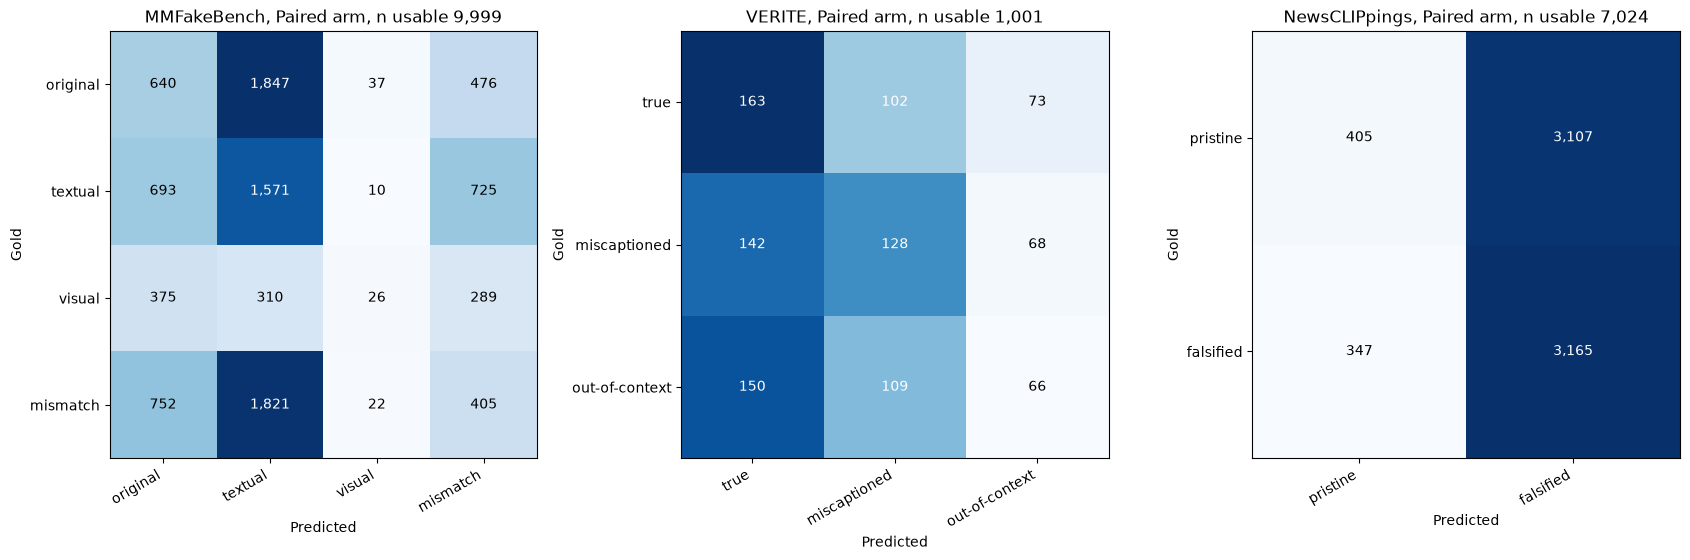

In [4]:
SHORT = {
    "textual_veracity_distortion": "textual",
    "visual_veracity_distortion": "visual",
}

keys = ["mm_paired", "verite_paired", "ncp"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))

for ax, key in zip(axes, keys):
    run = RUNS[key]
    cm = np.array(run["confusion"])
    labels = [SHORT.get(lab, lab) for lab in run["labels"]]
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Gold")
    ax.set_title(f"{run['dataset']}, {run['arm']} arm, n usable {run['counts']['usable']:,}")
    threshold = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black",
            )

plt.tight_layout()
plt.savefig(FIG / "02_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## Per-class results

Precision, recall and F1 for every class in every run, with class support.

In [5]:
rows = []
for run in R["runs"]:
    for lab in run["labels"]:
        pc = run["per_class"][lab]
        rows.append({
            "Dataset": run["dataset"],
            "Arm": run["arm"],
            "Class": lab,
            "Support": pc["support"],
            "Precision %": f"{100 * pc['precision']:.1f}",
            "Recall %": f"{100 * pc['recall']:.1f}",
            "F1 %": f"{100 * pc['f1']:.1f}",
        })

per_class = pd.DataFrame(rows)
display(per_class)

,Dataset,Arm,Class,Support,Precision %,Recall %,F1 %
0,MMFakeBench,Paired,original,3000,26.0,21.3,23.4
1,MMFakeBench,Paired,textual_veracity_distortion,2999,28.3,52.4,36.8
2,MMFakeBench,Paired,visual_veracity_distortion,1000,27.4,2.6,4.7
3,MMFakeBench,Paired,mismatch,3000,21.4,13.5,16.5
4,MMFakeBench,Text only,original,3000,26.4,22.1,24.1
5,MMFakeBench,Text only,textual_veracity_distortion,3000,29.6,56.9,38.9
6,MMFakeBench,Text only,visual_veracity_distortion,1000,12.4,4.8,6.9
7,MMFakeBench,Text only,mismatch,3000,28.1,12.5,17.3
8,MMFakeBench,Image only,original,329,29.4,49.2,36.8
9,MMFakeBench,Image only,textual_veracity_distortion,273,17.8,13.6,15.4


## Paired minus text-only differences

Each difference is the paired (image + text) arm minus the text-only arm, in percentage points. The MMFakeBench full-test interval resamples groups of rows. The image-sample and VERITE intervals resample image clusters.

In [6]:
d = R["differences"]

def diff_row(label, delta, lo, hi, n, clusters):
    return {
        "label": label,
        "delta_pp": round(100 * delta, 2),
        "ci_low_pp": round(100 * lo, 2),
        "ci_high_pp": round(100 * hi, 2),
        "n": n,
        "clusters": clusters,
        "range spans zero": bool(lo <= 0 <= hi),
    }

mm_full = d["mm_full"]
mm_sample = d["mm_sample"]
verite = d["verite"]

diffs = pd.DataFrame([
    diff_row(
        "MMFakeBench full test, accuracy",
        mm_full["accuracy_a"] - mm_full["accuracy_b"],
        mm_full["difference_95"][0], mm_full["difference_95"][1],
        mm_full["shared_rows"], "not recorded",
    ),
    diff_row(
        "MMFakeBench image sample, accuracy",
        mm_sample["accuracy"],
        mm_sample["accuracy_95"][0], mm_sample["accuracy_95"][1],
        mm_sample["n_shared"], mm_sample["clusters"],
    ),
    diff_row(
        "MMFakeBench image sample, macro-F1",
        mm_sample["macro_f1"],
        mm_sample["macro_f1_95"][0], mm_sample["macro_f1_95"][1],
        mm_sample["n_shared"], mm_sample["clusters"],
    ),
    diff_row(
        "VERITE, accuracy",
        verite["accuracy"],
        verite["accuracy_95"][0], verite["accuracy_95"][1],
        verite["n_shared"], verite["clusters"],
    ),
    diff_row(
        "VERITE, macro-F1",
        verite["macro_f1"],
        verite["macro_f1_95"][0], verite["macro_f1_95"][1],
        verite["n_shared"], verite["clusters"],
    ),
])
display(diffs)

,label,delta_pp,ci_low_pp,ci_high_pp,n,clusters,range spans zero
0,"MMFakeBench full test, accuracy",-1.51,-2.44,-0.54,9999,not recorded,False
1,"MMFakeBench image sample, accuracy",0.10,-2.71,3.00,1000,996,True
2,"MMFakeBench image sample, macro-F1",-1.66,-4.87,1.63,1000,996,True
3,"VERITE, accuracy",-0.20,-3.60,3.10,1001,663,True
4,"VERITE, macro-F1",-1.25,-4.60,2.11,1001,663,True


The MMFakeBench difference above is pooled across source pairs, and notebook 03 splits it by source pair.

## NewsCLIPpings details

Accuracy by prompt strategy, and the area under the curve for each score. An AUC below 0.5 ranks the labels in the wrong direction on average.

In [7]:
ncp = RUNS["ncp"]

strategy_rows = []
for strategy in sorted(ncp["per_strategy"], key=lambda s: int(s)):
    ps = ncp["per_strategy"][strategy]
    strategy_rows.append({
        "Strategy": strategy,
        "n": ps["n"],
        "Accuracy %": f"{100 * ps['accuracy']:.1f}",
    })
per_strategy = pd.DataFrame(strategy_rows)
display(per_strategy)

auc_rows = []
for name, value in ncp["auc"].items():
    auc_rows.append({
        "Score": name,
        "AUC": round(value, 3),
        "Reading": "below chance" if value < 0.5 else "at or above chance",
    })
auc_table = pd.DataFrame(auc_rows)
display(auc_table)

,Strategy,n,Accuracy %
0,0,1756,50.3
1,1,1756,51.3
2,2,1756,51.4
3,3,1756,50.4


,Score,AUC,Reading
0,out_of_context,0.468,below chance
1,wrong_image,0.448,below chance


In [8]:
failures = []

for run in R["runs"]:
    labels = run["labels"]
    cm = np.array(run["confusion"])
    total = cm.sum()

    recomputed = np.trace(cm) / total
    if abs(recomputed - run["accuracy"]) > 1e-9:
        failures.append((run["key"], "accuracy", recomputed, run["accuracy"]))

    for i, lab in enumerate(labels):
        if cm[i].sum() != run["support"][lab]:
            failures.append((run["key"], f"row sum for {lab}", cm[i].sum(), run["support"][lab]))

    counts = run["counts"]
    if counts["attempted"] != counts["usable"] + counts["error"] + counts["blocked"]:
        failures.append((run["key"], "attempted identity", counts["attempted"], counts))

    if sum(run["support"].values()) != counts["usable"]:
        failures.append((run["key"], "sum(support) vs usable", sum(run["support"].values()), counts["usable"]))

assert not failures, failures
print("all checks passed")

all checks passed


## Takeaways

- On MMFakeBench, the paired arm reaches 26.4% accuracy against 30.0% for always answering original, so it is below that floor on accuracy. Its macro-F1 of 20.4% is above the 11.5% majority floor. The test split is post-hoc, so these are descriptive numbers.
- On VERITE, the paired arm reaches 35.7% accuracy against the 33.3% random floor. Its 95% range of [33.17, 38.16] includes the floor, so the result is not separated from guessing.
- On NewsCLIPpings, the paired arm reaches 50.8% accuracy with a 95% range of [49.78, 51.81], which includes the 50.0% coin-flip floor. Both AUCs (0.468 and 0.448) are below chance.
- Text-only predictions are better calibrated on MMFakeBench, with ECE of 1.2% against 8.2% for the paired arm. Adding the image lowers MMFakeBench accuracy by 1.51 percentage points (range -2.44 to -0.54), while the VERITE and image-sample differences span zero.